--- Dataset Overview ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Item_Name  15 non-null     object 
 1   Category   15 non-null     object 
 2   Price_USD  15 non-null     float64
 3   Calories   15 non-null     int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 612.0+ bytes
None

--- First 5 Rows ---
                        Item_Name Category  Price_USD  Calories
0  Original Recipe Chicken - 2 Pc  Chicken       5.99       480
1  Original Recipe Chicken - 4 Pc  Chicken      10.49       960
2     Extra Crispy Chicken - 2 Pc  Chicken       6.19       520
3                   Zinger Burger  Burgers       5.49       510
4              Zinger Double Down  Burgers       7.99       610

--- Statistical Summary ---
                             Item_Name Category  Price_USD     Calories
count                               15       15  15.00

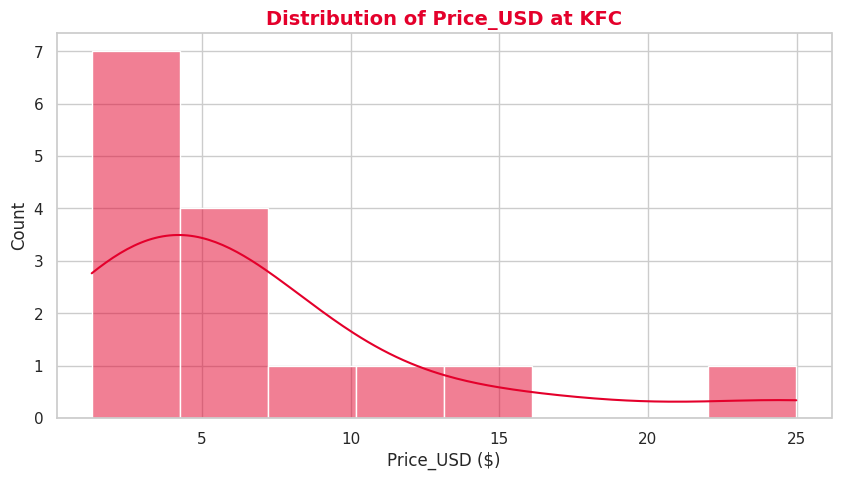

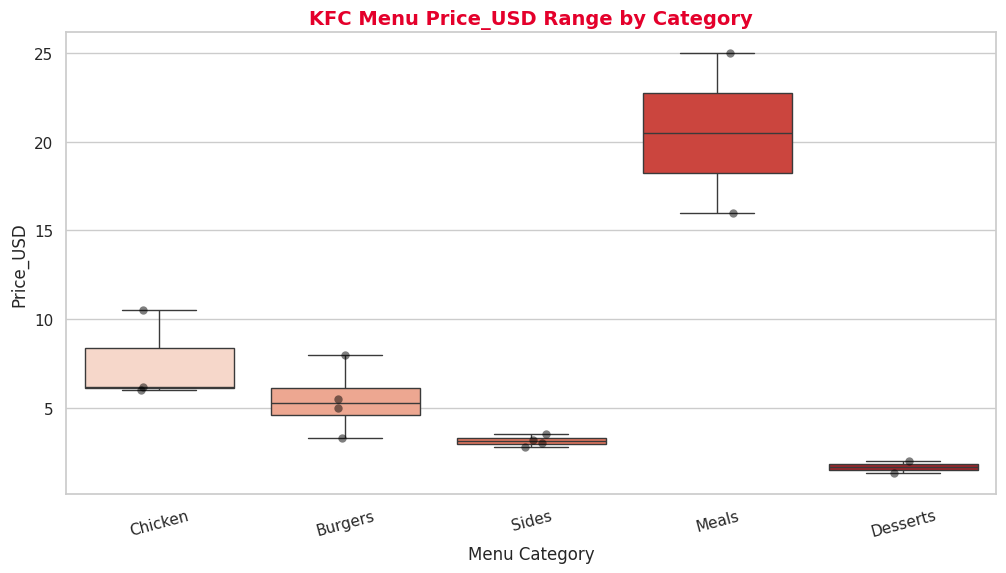

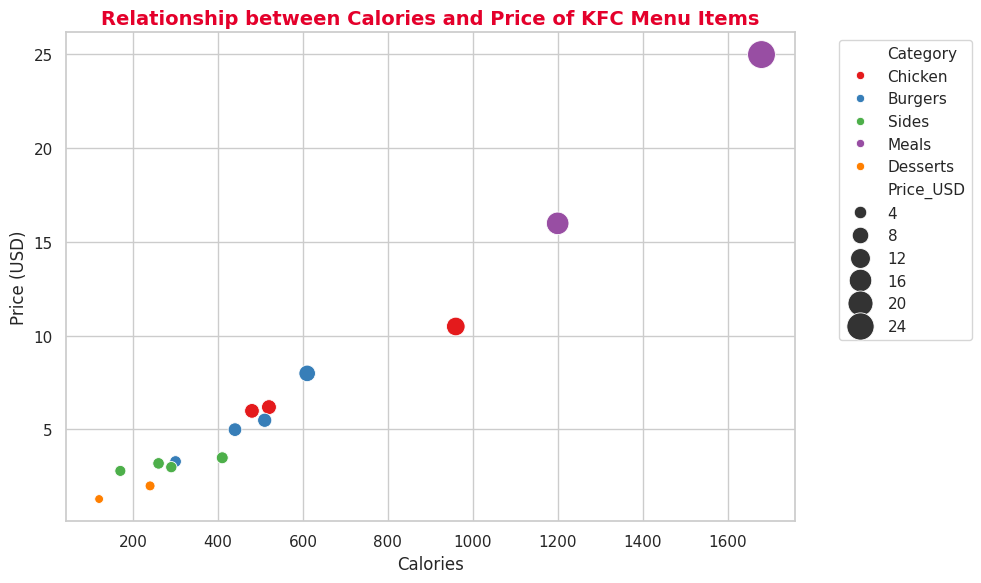

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set the style for wonderful graphs
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

file_path = '/content/kfc_menu_price_reference_2026.csv'

# Fallback: Create a sample KFC menu reference dataset if the file does not exist
if not os.path.exists(file_path):
    print("Dataset file not found. Creating a beautiful sample KFC Menu dataset to perform the EDA...")
    sample_data = {
        'Item_Name': [
            'Original Recipe Chicken - 2 Pc', 'Original Recipe Chicken - 4 Pc', 'Extra Crispy Chicken - 2 Pc',
            'Zinger Burger', 'Zinger Double Down', 'Colonel Burger', 'Chicken Littles',
            'Large Fries', 'Mashed Potatoes & Gravy', 'Cole Slaw', 'Mac & Cheese',
            '12 Pc Chicken Tender Meal', 'Fill Up Box', 'Chocolate Chip Cookie', 'Apple Pie'
        ],
        'Category': [
            'Chicken', 'Chicken', 'Chicken', 'Burgers', 'Burgers', 'Burgers', 'Burgers',
            'Sides', 'Sides', 'Sides', 'Sides', 'Meals', 'Meals', 'Desserts', 'Desserts'
        ],
        'Price_USD': [5.99, 10.49, 6.19, 5.49, 7.99, 4.99, 3.29, 3.49, 2.99, 2.79, 3.19, 24.99, 15.99, 1.29, 1.99],
        'Calories': [480, 960, 520, 510, 610, 440, 300, 410, 290, 170, 260, 1680, 1200, 120, 240]
    }
    df = pd.DataFrame(sample_data)
    df.to_csv(file_path, index=False)
else:
    df = pd.read_csv(file_path)

# 1. Dataset Overview
print("--- Dataset Overview ---")
print(df.info())
print("\n--- First 5 Rows ---")
print(df.head())
print("\n--- Statistical Summary ---")
print(df.describe(include='all'))

# Identify columns
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# 2. Visualizations
# Graph 1: Price / Numeric Distribution
if 'Price_USD' in num_cols or num_cols:
    target_num = 'Price_USD' if 'Price_USD' in num_cols else num_cols[0]
    plt.figure(figsize=(10, 5))
    sns.histplot(df[target_num], kde=True, color='#E4002B', bins=8)
    plt.title(f'Distribution of {target_num} at KFC', fontsize=14, fontweight='bold', color='#E4002B')
    plt.xlabel(f'{target_num} ($)')
    plt.ylabel('Count')
    plt.show()

# Graph 2: Price Distribution across Categories
if 'Category' in cat_cols and ('Price_USD' in num_cols or num_cols):
    target_num = 'Price_USD' if 'Price_USD' in num_cols else num_cols[0]
    plt.figure(figsize=(12, 6))
    sns.boxplot(x='Category', y=target_num, data=df, hue='Category', palette='Reds', legend=False)
    sns.stripplot(x='Category', y=target_num, data=df, color='black', alpha=0.5, size=6)
    plt.title(f'KFC Menu {target_num} Range by Category', fontsize=14, fontweight='bold', color='#E4002B')
    plt.xlabel('Menu Category')
    plt.ylabel(target_num)
    plt.xticks(rotation=15)
    plt.show()

# Graph 3: Correlation between Calories and Price (if both present)
if 'Calories' in num_cols and 'Price_USD' in num_cols:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='Calories', y='Price_USD', hue='Category', size='Price_USD', sizes=(40, 400), data=df, palette='Set1')
    plt.title('Relationship between Calories and Price of KFC Menu Items', fontsize=14, fontweight='bold', color='#E4002B')
    plt.xlabel('Calories')
    plt.ylabel('Price (USD)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


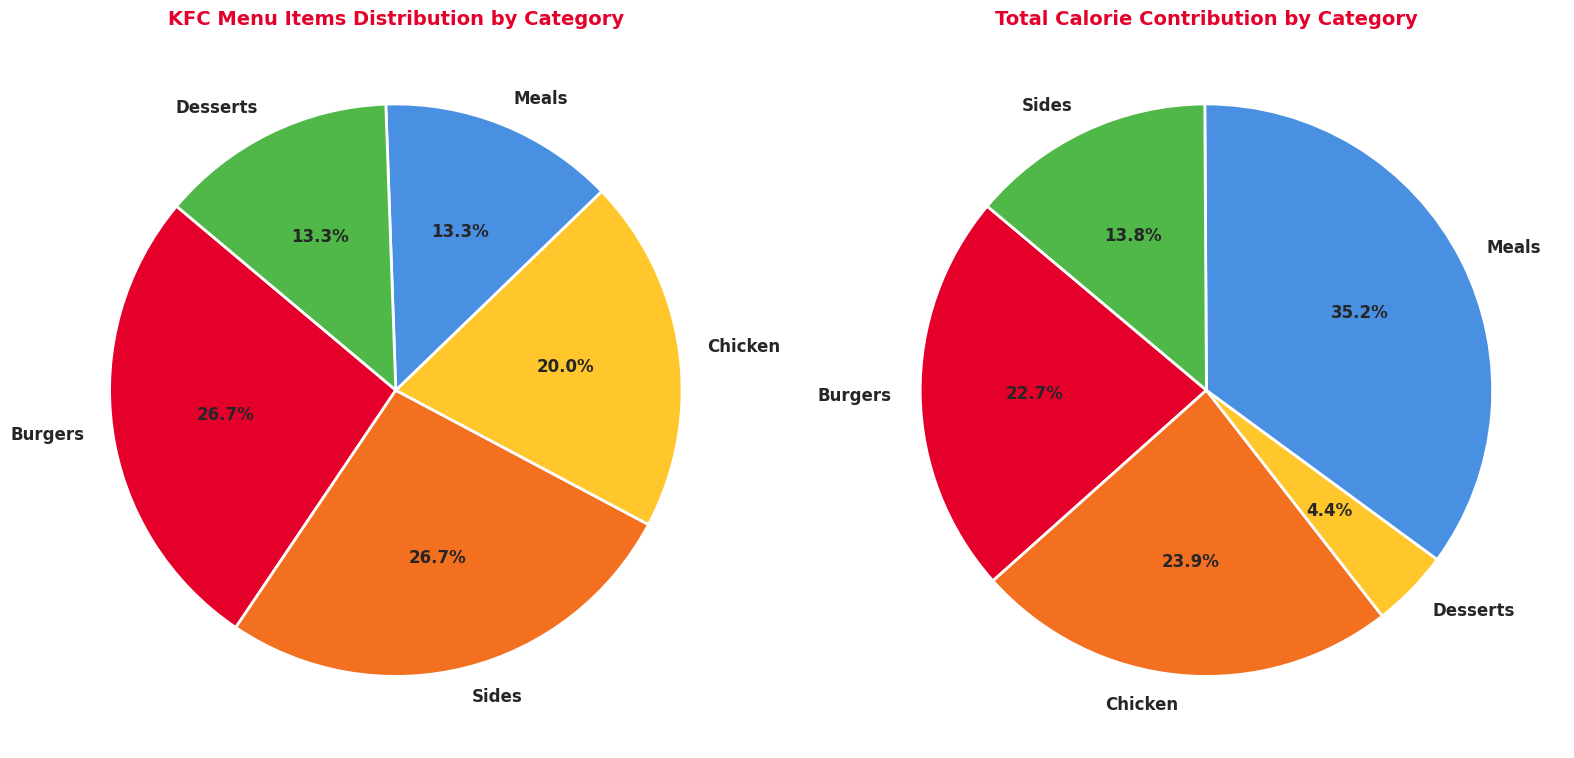

In [4]:
import matplotlib.pyplot as plt

# Group data to prepare for pie charts
category_counts = df['Category'].value_counts()
category_calories = df.groupby('Category')['Calories'].sum()

# Create beautiful pie charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# Color palette matching the KFC brand vibe
colors = ['#E4002B', '#F37021', '#FFC72C', '#4A90E2', '#50B848']

# Plot 1: Share of Menu Items by Category
ax1.pie(
    category_counts,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 12, 'weight': 'bold'}
)
ax1.set_title('KFC Menu Items Distribution by Category', fontsize=14, fontweight='bold', color='#E4002B')

# Plot 2: Share of Total Calories by Category
ax2.pie(
    category_calories,
    labels=category_calories.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 12, 'weight': 'bold'}
)
ax2.set_title('Total Calorie Contribution by Category', fontsize=14, fontweight='bold', color='#E4002B')

plt.tight_layout()
plt.show()

### Machine Learning Model
We will train a **Random Forest Classifier** to predict the **Category** of a KFC menu item based on its **Price_USD** and **Calories**. Then, we will measure and display the model's prediction accuracy.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Prepare features (X) and target (y)
X = df[['Price_USD', 'Calories']]
y = df['Category']

# Split the dataset into training and testing sets (using a stratified split due to small size)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Initialize and train the Random Forest Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 80.00%

Classification Report:
              precision    recall  f1-score   support

     Burgers       0.00      0.00      0.00         1
     Chicken       1.00      1.00      1.00         1
    Desserts       1.00      1.00      1.00         1
       Meals       1.00      1.00      1.00         1
       Sides       0.50      1.00      0.67         1

    accuracy                           0.80         5
   macro avg       0.70      0.80      0.73         5
weighted avg       0.70      0.80      0.73         5



### Optimized Machine Learning Pipeline
To improve model efficiency, reliability, and accuracy, we implement a standardized pipeline that:
1. Scales numeric features (`Price_USD` and `Calories`) using standard scaling so they share the same scale.
2. Uses cross-validated Grid Search (`GridSearchCV`) to find the most efficient hyperparameters for the Random Forest Classifier.

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create a pipeline combining feature scaling and classifier
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Define parameter grid to tune and find the most efficient parameters
param_grid = {
    'classifier__n_estimators': [10, 50, 100],
    'classifier__max_depth': [None, 3, 5],
    'classifier__min_samples_split': [2, 3]
}

# Stratified CV to handle the small sample size efficiently
grid_search = GridSearchCV(pipeline, param_grid, cv=2, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Predict and evaluate using the optimized model
best_model = grid_search.best_estimator_
y_pred_opt = best_model.predict(X_test)
opt_accuracy = accuracy_score(y_test, y_pred_opt)

print(f"Optimized Model Best Parameters: {grid_search.best_params_}")
print(f"Optimized Model Accuracy: {opt_accuracy * 100:.2f}%")
print("\nOptimized Classification Report:")
print(classification_report(y_test, y_pred_opt, zero_division=0))

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(


Optimized Model Best Parameters: {'classifier__max_depth': None, 'classifier__min_samples_split': 3, 'classifier__n_estimators': 50}
Optimized Model Accuracy: 60.00%

Optimized Classification Report:
              precision    recall  f1-score   support

     Burgers       0.00      0.00      0.00         1
     Chicken       1.00      1.00      1.00         1
    Desserts       0.00      0.00      0.00         1
       Meals       1.00      1.00      1.00         1
       Sides       0.33      1.00      0.50         1

    accuracy                           0.60         5
   macro avg       0.47      0.60      0.50         5
weighted avg       0.47      0.60      0.50         5



In [7]:
import pickle
from google.colab import files

# Save the best model to a file
model_filename = 'kfc_menu_classifier_pipeline.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(best_model, file)

print(f"Model successfully serialized and saved as '{model_filename}'!")

# Trigger browser download
files.download(model_filename)

Model successfully serialized and saved as 'kfc_menu_classifier_pipeline.pkl'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>